# 05 · Weight of Evidence (WoE) e Information Value (IV)
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** `04_train`, `04_test` · **Salida:** `05_train_woe`, `05_test_woe`,
`artifacts/woe_maps.joblib`, `reports/iv_table.json`.

El WoE es la técnica con la que se construyen los **scorecards** que aprueban los reguladores.
Tiene una propiedad rara y valiosa: **trata los nulos y los atípicos sin despeinarse**, porque no
trabaja con los valores sino con **grupos**. Por eso va *antes* de la imputación (NB06): no la
necesita.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, SEED, load_stage, save_stage, save_artifact, save_report, save_table,
    set_plot_theme,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

set_plot_theme()

train_raw = load_stage("04_train")
test_raw = load_stage("04_test")

# Columnas de score que añadió el NB04 al test (no son features)
cols_score = ["maha_d2", "score_iso", "score_lof", "flag_outlier"]

y_train = train_raw[TARGET]
y_test = test_raw[TARGET]
X_train = train_raw.drop(columns=[TARGET, SEGMENT_COL])
X_test = test_raw.drop(columns=[TARGET, SEGMENT_COL] + [c for c in cols_score if c in test_raw])

# Alias para el código de esta sesión
seed = SEED
target = TARGET

print("TRAIN:", X_train.shape, "| TEST:", X_test.shape)
print("Columnas:", list(X_train.columns))

TRAIN: (447, 11) | TEST: (123, 11)
Columnas: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']


## 5.0 La matemática, con un ejemplo a mano

Antes de la teoría formal, hagamos **un caso a mano** para que las fórmulas dejen de ser símbolos.

Supongamos una variable `Zona` con 3 categorías y estos conteos (evento = crédito rechazado):

| Zona | No-evento (buenos) | Evento (malos) |
|---|---|---|
| A | 80 | 20 |
| B | 50 | 50 |
| C | 30 | 70 |
| **Total** | **160** | **140** |

**WoE de cada bin** = ln( %buenos_bin / %malos_bin ), donde los % son sobre el total de su clase:

In [2]:
ejemplo = pd.DataFrame({"buenos": [80, 50, 30], "malos": [20, 50, 70]}, index=["A", "B", "C"])
tot_b, tot_m = ejemplo["buenos"].sum(), ejemplo["malos"].sum()

ejemplo["%buenos"] = ejemplo["buenos"] / tot_b
ejemplo["%malos"] = ejemplo["malos"] / tot_m
ejemplo["WoE"] = np.log(ejemplo["%buenos"] / ejemplo["%malos"])
ejemplo["IV_bin"] = (ejemplo["%buenos"] - ejemplo["%malos"]) * ejemplo["WoE"]

print(ejemplo.round(4).to_string())
print(f"\nInformation Value TOTAL = suma de IV_bin = {ejemplo['IV_bin'].sum():.4f}")
print()
print("Lectura:")
print("  · Zona A: WoE > 0 → MÁS buenos de lo esperado → MENOS riesgo")
print("  · Zona C: WoE < 0 → MÁS malos de lo esperado  → MÁS riesgo")
print("  · El IV total resume, en un solo número, cuánto SEPARA esta variable a buenos de malos.")
print()
print(">> Con nuestra convención (evento=1=malo), WoE alto = menos riesgo. Retenlo: en 5.9")
print("   veremos que el coeficiente de la regresión sobre estas variables sale ≈ −1, y por qué.")

   buenos  malos  %buenos  %malos     WoE  IV_bin
A      80     20   0.5000  0.1429  1.2528  0.4474
B      50     50   0.3125  0.3571 -0.1335  0.0060
C      30     70   0.1875  0.5000 -0.9808  0.3065

Information Value TOTAL = suma de IV_bin = 0.7599

Lectura:
  · Zona A: WoE > 0 → MÁS buenos de lo esperado → MENOS riesgo
  · Zona C: WoE < 0 → MÁS malos de lo esperado  → MÁS riesgo
  · El IV total resume, en un solo número, cuánto SEPARA esta variable a buenos de malos.

>> Con nuestra convención (evento=1=malo), WoE alto = menos riesgo. Retenlo: en 5.9
   veremos que el coeficiente de la regresión sobre estas variables sale ≈ −1, y por qué.


### 5.1 Las fórmulas

El WoE se calcula **por cada bin (grupo) de una variable**. Para el bin $i$:

$$ WoE_i = \ln\left( \frac{\%\text{No-Evento}_i}{\%\text{Evento}_i} \right) $$

donde:

$$ \%\text{No-Evento}_i = \frac{\text{no-eventos en el bin } i}{\text{total de no-eventos}}
\qquad
\%\text{Evento}_i = \frac{\text{eventos en el bin } i}{\text{total de eventos}} $$

**Atención a un error clásico:** el denominador **NO** es la cantidad de registros del bin. Es el
total de eventos (o no-eventos) de **toda la muestra**. Es decir, el WoE compara *cómo se
distribuyen los malos* contra *cómo se distribuyen los buenos* a lo largo de los bins. Por eso
es robusto al desbalance de clases.

Y el **Information Value** resume el poder predictivo de la variable completa en **un solo número**:

$$ IV = \sum_{i} \left( \%\text{No-Evento}_i - \%\text{Evento}_i \right) \times WoE_i $$

El IV es siempre $\geq 0$: cuando $\%\text{No-Evento}_i > \%\text{Evento}_i$, el $WoE_i$ también
es positivo (el logaritmo de un número mayor a 1), así que el producto siempre suma positivo.

#### ⚠️ Convención de signo (la usaremos de forma CONSISTENTE en todo el notebook)

Usamos **`ln(%No-Evento / %Evento)`**, con el **evento = target = 1 = "crédito no otorgado" = malo**.
Con esta convención:

| Signo | Lectura | Interpretación de negocio |
|---|---|---|
| **WoE > 0** | El bin concentra **más buenos** que malos | Grupo de **menor riesgo** |
| **WoE = 0** | El bin se comporta como el promedio | Grupo **neutro**, no aporta información |
| **WoE < 0** | El bin concentra **más malos** que buenos | Grupo de **mayor riesgo** |

> **Ojo:** hay bibliografía que usa la fórmula invertida `ln(%Evento / %No-Evento)`. **Ninguna de
> las dos está mal**, pero invierte todos los signos y por lo tanto invierte la lectura. Lo grave
> no es elegir una u otra: lo grave es **mezclarlas dentro del mismo proyecto**. Fija la convención
> al inicio, documéntala y no la cambies.

### 5.2 Tabla de interpretación del Information Value

Esta es la tabla estándar de la industria (Siddiqi, *Credit Risk Scorecards*):

| Information Value | Poder predictivo |
|---|---|
| < 0.02 | **Inútil** — no aporta, candidata a descarte |
| 0.02 – 0.1 | **Débil** |
| 0.1 – 0.3 | **Medio** |
| 0.3 – 0.5 | **Fuerte** |
| > 0.5 | **Sospechoso** — demasiado bueno para ser verdad |

**El último tramo es el más importante de todos y el que menos se respeta.** Un IV > 0.5 en un
problema de crédito rara vez significa "encontramos la variable mágica". Casi siempre significa
una de estas tres cosas:

1. **Leakage**: la variable contiene información que en producción **todavía no existe** al momento
   de decidir (ej. usar `monto_desembolsado` para predecir si se aprueba el crédito: si hay monto
   desembolsado, ya sabemos que se aprobó).
2. **La variable es una consecuencia del target**, no una causa (causalidad invertida).
3. **Sobreajuste del binning**: creamos bins tan finos que cada uno tiene 3 registros y el WoE está
   memorizando ruido.

Regla práctica: **un IV > 0.5 no se celebra, se investiga.**

### 5.3 Ventajas y desventajas

**Ventajas**
- **Maneja de forma natural los valores perdidos**: el nulo se trata como **una categoría más** y
  recibe su propio WoE. No hay que imputar nada. Y esto es enorme, porque en banca **el nulo suele
  ser informativo**: que un cliente no tenga historial crediticio no es un dato faltante al azar,
  es un perfil de riesgo distinto. Imputar con la mediana **destruye** esa señal.
- **Maneja los valores atípicos**: al agrupar en bins, un ingreso de S/ 81,000 cae en el bin
  "ingreso alto" y pesa exactamente lo mismo que uno de S/ 20,000. El outlier deja de arrastrar
  el modelo.
- **La transformación se basa en el valor logarítmico de una distribución**, que es exactamente la
  escala en la que trabaja la regresión logística (log-odds). Por eso encajan tan bien.
- **Puede transformar una variable independiente para que establezca una relación monótona con la
  variable dependiente**, incluso si la relación original era no lineal (una U, por ejemplo).

**Desventajas**
- **Pérdida de información (variación)**: al agrupar en pocas categorías, se pierde la granularidad
  dentro de cada bin. Dos clientes con ingresos de S/ 3,000 y S/ 5,000 pueden terminar con el mismo
  WoE.
- **Es una medida univariante**: el IV mide cada variable **por separado y no considera la
  correlación entre las variables independientes**. Dos variables con IV alto pueden ser
  redundantes entre sí. **El IV sirve para descartar, no para elegir el modelo final.**
- **Es fácil de manipular / sobreajustar**: el efecto depende de cómo se creen las categorías. Si
  uno mueve los cortes hasta que el IV suba, está sobreajustando. Los bins se definen **antes** de
  ver el IV, con criterio de negocio y volumen mínimo por bin.

> 🚨 **Y la advertencia que atraviesa toda esta sección:** el WoE y el IV se calculan **SOLO sobre
> TRAIN** y se **aplican** a TEST. Calcularlos sobre todo el dataset es **leakage**. Lo vamos a
> demostrar con números en la sección 5.10.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 5.4 Construimos nuestra propia función de WoE / IV

Vamos a programarla desde cero (y no usar una librería) porque cada decisión de esta función es una
decisión de negocio que tenemos que entender.

**Decisión 1 — ¿Cómo agrupamos?**
- Variables **categóricas** → usamos las categorías tal cual.
- Variables **numéricas** → binning por **cuantiles** con `pd.qcut`, para que todos los bins tengan
  un volumen parecido (si usáramos `pd.cut`, con `ApplicantIncome` tendríamos un bin con 600
  clientes y otro con 2). Usamos `duplicates='drop'` porque cuando una variable está muy
  concentrada (ej. `CoapplicantIncome`, llena de ceros) varios cuantiles caen en el mismo valor y
  `qcut` fallaría con un error.
- Variables **numéricas con pocos valores distintos** (`Credit_History` tiene 0 y 1;
  `Loan_Amount_Term` tiene 10 plazos) → aunque sean `float`, son **categóricas de negocio**. No
  tiene ningún sentido cortarlas en cuantiles.

**Decisión 2 — Los nulos son una categoría (`'NULO'`)**, no un problema a imputar.

**Decisión 3 — Suavizado de Laplace.** Esta es crítica y la explicamos aparte.

#### ¿Por qué necesitamos el suavizado de Laplace?

Miremos la fórmula otra vez: $WoE_i = \ln(\%\text{No-Evento}_i \,/\, \%\text{Evento}_i)$.

¿Qué pasa si un bin tiene **cero eventos**? El denominador es 0 → la división explota → el WoE
es $+\infty$. Y si tiene cero no-eventos, el WoE es $-\infty$. En ambos casos el IV se vuelve
`inf` y la variable queda inutilizable. Esto **no es un caso raro**: con unos pocos cientos de
registros repartidos en 10 bins, basta un bin pequeño y puro para romper todo. En nuestro propio
train, `Loan_Amount_Term = 12` tiene **un solo caso**: un bin de un cliente es, por definición,
100% puro hacia donde caiga ese cliente.

La solución es el **suavizado de Laplace**: sumamos una constante $\alpha$ (usamos 0.5) al conteo
de eventos y de no-eventos de cada bin **antes** de calcular las proporciones:

$$ \%\text{Evento}_i = \frac{\text{eventos}_i + \alpha}{\text{total eventos} + \alpha \cdot k}
\qquad\qquad
\%\text{No-Evento}_i = \frac{\text{no-eventos}_i + \alpha}{\text{total no-eventos} + \alpha \cdot k} $$

donde $k$ es el número de bins. Sumar $\alpha \cdot k$ en el denominador mantiene la propiedad de
que las proporciones **siguen sumando 1**, así que el IV se mantiene interpretable.

La lectura estadística es bonita: es equivalente a agregar medio caso ficticio de cada clase en
cada bin. Es un **prior**. Le estamos diciendo al modelo *"no me creo que este bin sea 100% puro
solo porque vi 3 casos"*. Y no es solo un parche numérico: es lo **honesto**. Un bin con 3 clientes
y 0 malos **no** tiene evidencia de riesgo cero — tiene evidencia insuficiente. El suavizado
encoge automáticamente el WoE de los bins pequeños hacia 0 (neutro) y casi no toca los grandes.

In [4]:
def _binear(serie, n_bins=10, edges=None, etiqueta_nulo='NULO'):
    """
    Agrupa una serie en bins y devuelve la serie agrupada + los cortes usados.

    Aplica la lógica de la Decisión 1: categórica -> tal cual; numérica -> cuantiles;
    numérica de baja cardinalidad -> tal cual. Los nulos SIEMPRE van a su propia
    categoría 'NULO'.

    Parámetros
    ----------
    serie : pd.Series
    n_bins : int
        Número máximo de bins para variables numéricas.
    edges : array o None
        Si se pasan cortes ya calculados (por ejemplo, los aprendidos en TRAIN), se
        reutilizan en lugar de recalcularlos. ESTA ES LA CLAVE PARA NO TENER LEAKAGE.
    etiqueta_nulo : str

    Retorna
    -------
    (pd.Categorical ordenado, edges o None)
    """
    nulos = serie.isna()

    def _empaquetar(valores_str, categorias):
        """Arma un Categorical ordenado y agrega 'NULO' al final si corresponde."""
        valores_str = valores_str.where(~nulos, etiqueta_nulo)
        if nulos.any():
            categorias = list(categorias) + [etiqueta_nulo]
        return pd.Categorical(valores_str, categories=categorias, ordered=True)

    # --- Caso A: cortes ya aprendidos en TRAIN -> los reutilizamos tal cual ---
    if edges is not None:
        b = pd.cut(serie, bins=edges)
        return _empaquetar(b.astype(str), [str(c) for c in b.cat.categories]), edges

    es_numerica = pd.api.types.is_numeric_dtype(serie)

    # --- Caso B: categórica, o numérica de baja cardinalidad -> categorías tal cual ---
    if (not es_numerica) or (serie.nunique(dropna=True) <= n_bins):
        cats = sorted(serie.dropna().unique().tolist(), key=str)
        return _empaquetar(serie.astype(str), [str(c) for c in cats]), None

    # --- Caso C: numérica continua -> binning por cuantiles ---
    _, edges = pd.qcut(serie, q=n_bins, duplicates='drop', retbins=True)
    if len(edges) < 3:  # la variable está tan concentrada que no se pudo partir
        cats = sorted(serie.dropna().unique().tolist(), key=str)
        return _empaquetar(serie.astype(str), [str(c) for c in cats]), None

    # Abrimos los extremos a -inf / +inf: en TEST puede aparecer un ingreso mayor
    # al máximo visto en TRAIN, y si no lo hacemos ese cliente quedaría sin bin.
    edges = edges.astype(float).copy()
    edges[0], edges[-1] = -np.inf, np.inf

    b = pd.cut(serie, bins=edges)
    return _empaquetar(b.astype(str), [str(c) for c in b.cat.categories]), edges


def calcular_woe_iv(df, feature, target, n_bins=10, alpha=0.5, edges=None):
    """
    Calcula la tabla de Weight of Evidence y el Information Value de una variable.

    Convención de signo: WoE = ln(%No-Evento / %Evento), con evento = target = 1.
    Por lo tanto WoE > 0 => bin de MENOR riesgo; WoE < 0 => bin de MAYOR riesgo.

    Parámetros
    ----------
    df : pd.DataFrame
        Debe contener `feature` y `target`. IMPORTANTE: debe ser SOLO TRAIN.
    feature : str
    target : str
        Columna binaria 0/1 donde 1 = evento (en nuestro caso, crédito no otorgado).
    n_bins : int, default 10
        Número máximo de bins para variables numéricas continuas.
    alpha : float, default 0.5
        Constante de suavizado de Laplace. Evita ln(0) = -inf y encoge hacia 0 el
        WoE de los bins con poca evidencia.
    edges : array o None
        Cortes preexistentes (aprendidos en TRAIN) a reutilizar.

    Retorna
    -------
    tabla : pd.DataFrame
        bin, n, %n, eventos, no_eventos, tasa_evento, %evento, %no_evento, WoE, IV_parcial
    iv : float
    """
    binned, _ = _binear(df[feature], n_bins=n_bins, edges=edges)

    tmp = pd.DataFrame({'bin': binned, 'y': np.asarray(df[target])})
    # observed=True: solo bins que realmente aparecen. El Categorical mantiene el orden.
    g = tmp.groupby('bin', observed=True)['y'].agg(n='count', eventos='sum')
    g['no_eventos'] = g['n'] - g['eventos']

    k = len(g)
    total_ev, total_no_ev = g['eventos'].sum(), g['no_eventos'].sum()

    g['%n'] = g['n'] / g['n'].sum()
    g['tasa_evento'] = g['eventos'] / g['n']

    # Suavizado de Laplace: sumamos alpha arriba y alpha*k abajo, de modo que las
    # proporciones sigan sumando exactamente 1.
    g['%evento'] = (g['eventos'] + alpha) / (total_ev + alpha * k)
    g['%no_evento'] = (g['no_eventos'] + alpha) / (total_no_ev + alpha * k)

    g['WoE'] = np.log(g['%no_evento'] / g['%evento'])
    g['IV_parcial'] = (g['%no_evento'] - g['%evento']) * g['WoE']

    tabla = g.reset_index()[['bin', 'n', '%n', 'eventos', 'no_eventos', 'tasa_evento',
                             '%evento', '%no_evento', 'WoE', 'IV_parcial']]
    tabla['bin'] = tabla['bin'].astype(str)
    return tabla, tabla['IV_parcial'].sum()


def poder_predictivo(iv):
    """Traduce el IV a la etiqueta estándar de la industria."""
    if iv < 0.02:
        return 'Inútil'
    elif iv < 0.1:
        return 'Débil'
    elif iv < 0.3:
        return 'Medio'
    elif iv < 0.5:
        return 'Fuerte'
    return 'Sospechoso (revisar leakage)'

### 5.5 Primer ejemplo: `Credit_History` (categórica **con nulos**)

Recordemos: **calculamos sobre `X_train` / `y_train`, NUNCA sobre el dataset completo.**
Armamos un DataFrame de trabajo que junte las features de train con su target.

In [5]:
# Base de trabajo: SOLO TRAIN. Este `.copy()` y este `train` son la frontera anti-leakage.
train = X_train.copy()
train[target] = y_train

print(f"Registros de TRAIN : {len(train)}")
print(f"Tasa de evento     : {train[target].mean():.2%}  (target=1 = crédito NO otorgado)")

Registros de TRAIN : 447
Tasa de evento     : 29.08%  (target=1 = crédito NO otorgado)


In [6]:
tabla_ch, iv_ch = calcular_woe_iv(train, 'Credit_History', target)

print(f"Information Value de Credit_History = {iv_ch:.4f}  ->  {poder_predictivo(iv_ch)}\n")
tabla_ch.round(4)

Information Value de Credit_History = 1.3165  ->  Sospechoso (revisar leakage)



,bin,n,%n,eventos,no_eventos,tasa_evento,%evento,%no_evento,WoE,IV_parcial
0,0.0,55,0.1230,50,5,0.9091,0.3840,0.0173,-3.1018,1.1376
1,1.0,356,0.7964,71,285,0.1994,0.5437,0.8964,0.4999,0.1763
2,NULO,36,0.0805,9,27,0.2500,0.0722,0.0863,0.1783,0.0025


In [7]:
# ¿A quién se parece el NULO? En vez de suponerlo, lo medimos: comparamos su WoE contra
# el de cada categoría observada. Todo se deriva de la tabla — si cambian los datos,
# cambia el veredicto solo.
fila = {str(b): r for b, r in zip(tabla_ch['bin'], tabla_ch.to_dict('records'))}

if 'NULO' in fila:
    woe_nulo = fila['NULO']['WoE']
    # ¿De qué categoría observada está más cerca en WoE?
    observadas = {b: r for b, r in fila.items() if b != 'NULO'}
    cercana = min(observadas, key=lambda b: abs(observadas[b]['WoE'] - woe_nulo))
    lejana = max(observadas, key=lambda b: abs(observadas[b]['WoE'] - woe_nulo))

    print(f"El bin NULO: {int(fila['NULO']['n'])} clientes ({fila['NULO']['%n']:.1%} del train)")
    print(f"  WoE(NULO)  = {woe_nulo:+.4f}   (tasa de evento {fila['NULO']['tasa_evento']:.1%})")
    print()
    for b, r in observadas.items():
        print(f"  WoE({b:>4s}) = {r['WoE']:+.4f}   (tasa de evento {r['tasa_evento']:.1%})"
              f"   -> distancia al NULO: {abs(r['WoE'] - woe_nulo):.4f}")
    print()
    print(f"-> El NULO se parece más a '{cercana}' (distancia {abs(observadas[cercana]['WoE'] - woe_nulo):.2f})")
    print(f"   y menos a '{lejana}' (distancia {abs(observadas[lejana]['WoE'] - woe_nulo):.2f}).")

    # ¿Merece el nulo su propia categoría, o imputarlo con la moda sería inocuo?
    # Medimos la brecha contra la categoría más cercana en relación al rango total de
    # WoE de la variable: es la escala en la que esta variable "habla".
    brecha_cercana = abs(observadas[cercana]['WoE'] - woe_nulo)
    rango_total = tabla_ch['WoE'].max() - tabla_ch['WoE'].min()
    peso_brecha = brecha_cercana / rango_total
    print()
    print(f"   La brecha con '{cercana}' es el {peso_brecha:.0%} del rango total de WoE de la variable.")
    if peso_brecha < 0.10:
        print(f"   -> A esta escala, el NULO y '{cercana}' son casi el mismo grupo: imputar el nulo")
        print(f"      con '{cercana}' probablemente NO habría hecho daño.")
    else:
        print(f"   -> El NULO NO es un clon de '{cercana}': tiene perfil propio, y darle su propio")
        print(f"      WoE lo respeta. Imputarlo lo habría empujado a un riesgo que no es el suyo.")

    # La honestidad estadística: ¿alcanza la evidencia para cerrar el tema?
    n_nulo = int(fila['NULO']['n'])
    print()
    print(f"   ⚠️  OJO con el tamaño: son {n_nulo} clientes. Con esa evidencia, la diferencia entre")
    print(f"      {fila['NULO']['tasa_evento']:.1%} y {observadas[cercana]['tasa_evento']:.1%} de tasa de evento "
          f"es perfectamente compatible con el azar.")
    print(f"      Lo que la tabla SÍ zanja es de qué lado NO está: '{lejana}' queda a "
          f"{abs(observadas[lejana]['WoE'] - woe_nulo):.2f} de distancia.")

El bin NULO: 36 clientes (8.1% del train)
  WoE(NULO)  = +0.1783   (tasa de evento 25.0%)

  WoE( 0.0) = -3.1018   (tasa de evento 90.9%)   -> distancia al NULO: 3.2801
  WoE( 1.0) = +0.4999   (tasa de evento 19.9%)   -> distancia al NULO: 0.3217

-> El NULO se parece más a '1.0' (distancia 0.32)
   y menos a '0.0' (distancia 3.28).

   La brecha con '1.0' es el 9% del rango total de WoE de la variable.
   -> A esta escala, el NULO y '1.0' son casi el mismo grupo: imputar el nulo
      con '1.0' probablemente NO habría hecho daño.

   ⚠️  OJO con el tamaño: son 36 clientes. Con esa evidencia, la diferencia entre
      25.0% y 19.9% de tasa de evento es perfectamente compatible con el azar.
      Lo que la tabla SÍ zanja es de qué lado NO está: '0.0' queda a 3.28 de distancia.


**Cómo se lee esta tabla (y esto es lo importante de toda la sección):**

- **`Credit_History = 0.0`** (cliente con mal historial): WoE **negativo y grande**. Ahí se
  concentran los malos. Es el grupo de mayor riesgo, y no sorprende a nadie del negocio.
- **`Credit_History = 1.0`** (buen historial): WoE **positivo**. Grupo de menor riesgo.
- **`NULO`**: 👀 acá está lo interesante. Los clientes **sin dato** de historial crediticio
  reciben **su propio WoE**, sin que hayamos imputado nada.

Mira la salida de la celda de arriba: el nulo **no se parece a los dos grupos por igual**. La celda
mide su distancia en WoE contra cada categoría observada y dicta el veredicto sola — no hace falta
que lo adivinemos, y si mañana cambian los datos el veredicto cambia con ellos.

**Y ése es exactamente el punto, que es más profundo que el eslogan de "el WoE maneja los nulos":**
nosotros no *sabíamos* dónde iba a caer el nulo antes de mirar. El WoE convierte *"¿con qué
imputo?"* de una **suposición** en una **pregunta empírica con respuesta**. El nulo se sienta en la
tabla junto a las demás categorías y **muestra** a qué grupo se parece — y cuánto se despega de él.

Los dos desenlaces posibles son hallazgos, y ninguno es "el bueno":

- **Si el nulo cae encima de una categoría existente**, la imputación por la moda habría sido
  inocua. Bien: ahora lo sabes **con evidencia**, en vez de haberlo supuesto y tenido suerte.
- **Si el nulo tiene perfil propio**, imputarlo lo habría disfrazado de otro cliente y **borrado la
  señal**. Los clientes **"thin file"** (sin historial en el sistema financiero) suelen ser
  justamente eso: un segmento de riesgo propio.

> 🎯 **El punto que hay que llevarse:** el WoE no "salva" al nulo, lo **interroga**. Sea cual sea la
> respuesta, llegas al negocio con **evidencia** en vez de con un valor por defecto.

Un matiz que un buen analista agrega: mira el `n` de ese bin en la salida. Es **poca evidencia**
para cerrar el tema. Lo correcto no es concluir "ya sé cómo se comporta el nulo", sino ir al negocio
y preguntar **por qué falta ese dato** — si es un problema de carga del sistema o un tipo de cliente
real. La tabla te dice *qué* pasa; solo el negocio te dice *por qué*.

Ahora, la advertencia honesta: **este IV está en la zona "sospechosa" (> 0.5)**. Aplicando nuestra
propia regla, no lo celebramos: lo investigamos. En este dataset `Credit_History` es prácticamente
la variable con la que se tomó la decisión de aprobación — está muy cerca de ser el target
disfrazado. En un proyecto real habría que confirmar con el negocio **en qué momento** se registra
ese campo: si se completa *después* de evaluar el crédito, es leakage puro y hay que sacarla.

### 5.6 Segundo ejemplo: `ApplicantIncome` (numérica continua)

Acá `qcut` parte la variable en 10 grupos de igual volumen. Fíjate en los outliers de ingreso: no
los tocamos, no los recortamos, no los transformamos con logaritmo. Simplemente **caen en el
último bin**.

In [8]:
tabla_ai, iv_ai = calcular_woe_iv(train, 'ApplicantIncome', target)

print(f"Information Value de ApplicantIncome = {iv_ai:.4f}  ->  {poder_predictivo(iv_ai)}\n")
tabla_ai.round(4)

Information Value de ApplicantIncome = 0.0357  ->  Débil



,bin,n,%n,eventos,no_eventos,tasa_evento,%evento,%no_evento,WoE,IV_parcial
0,"(-inf, 2260.6]",45,0.1007,12,33,0.2667,0.0926,0.1040,0.1165,0.0013
1,"(2260.6, 2662.0]",45,0.1007,11,34,0.2444,0.0852,0.1071,0.2293,0.0050
2,"(2662.0, 3081.4]",44,0.0984,11,33,0.2500,0.0852,0.1040,0.1999,0.0038
3,"(3081.4, 3421.6]",45,0.1007,14,31,0.3111,0.1074,0.0978,-0.0934,0.0009
4,"(3421.6, 3859.0]",45,0.1007,14,31,0.3111,0.1074,0.0978,-0.0934,0.0009
5,"(3859.0, 4372.0]",44,0.0984,13,31,0.2955,0.1000,0.0978,-0.0220,0.0000
6,"(4372.0, 5043.6]",45,0.1007,17,28,0.3778,0.1296,0.0885,-0.3816,0.0157
7,"(5043.6, 6250.0]",47,0.1051,12,35,0.2553,0.0926,0.1102,0.1745,0.0031
8,"(6250.0, 8945.8]",42,0.0940,14,28,0.3333,0.1074,0.0885,-0.1935,0.0037
9,"(8945.8, inf]",45,0.1007,12,33,0.2667,0.0926,0.1040,0.1165,0.0013


In [9]:
# Medimos la (no) monotonicidad en vez de afirmarla: contamos cuántas veces el WoE
# cambia de dirección al recorrer los bins de menor a mayor ingreso.
woe_ai = tabla_ai['WoE'].values
cambios_signo_ai = int((np.sign(woe_ai[1:]) != np.sign(woe_ai[:-1])).sum())
cambios_direccion_ai = int((np.diff(np.sign(np.diff(woe_ai))) != 0).sum())

# Correlación de Spearman entre el orden del bin y el WoE: 1 = monótona creciente
# perfecta, -1 = decreciente perfecta, ~0 = no hay tendencia.
from scipy.stats import spearmanr
rho_ai, _ = spearmanr(np.arange(len(woe_ai)), woe_ai)

print(f"ApplicantIncome — diagnóstico de monotonicidad ({len(tabla_ai)} bins)")
print("-" * 62)
print(f"  Tasa de evento por bin : {', '.join(f'{t:.0%}' for t in tabla_ai['tasa_evento'])}")
print(f"  Rango de la tasa       : {tabla_ai['tasa_evento'].min():.0%} a {tabla_ai['tasa_evento'].max():.0%}"
      f"   (amplitud {tabla_ai['tasa_evento'].max() - tabla_ai['tasa_evento'].min():.0%})")
print(f"  El WoE cruza el cero   : {cambios_signo_ai} veces")
print(f"  Cambia de dirección    : {cambios_direccion_ai} veces  (una relación monótona: 0)")
print(f"  Spearman(bin, WoE)     : {rho_ai:+.3f}  (monótona perfecta: ±1)")
print()
es_monotona = cambios_direccion_ai == 0
print(f"  Veredicto: {'MONÓTONA' if es_monotona else 'NO monótona — el WoE sube y baja sin orden'}")
print(f"  IV = {iv_ai:.4f} -> '{poder_predictivo(iv_ai)}'")
if iv_ai < 0.02:
    print("  -> por debajo del umbral de descarte (0.02): candidata a salir del modelo.")
else:
    print(f"  -> zafa del umbral de descarte (0.02), pero por poco. Un IV así no sostiene")
    print(f"     ninguna historia de negocio: 'a más ingreso, menos riesgo' NO está en estos datos.")

ApplicantIncome — diagnóstico de monotonicidad (10 bins)
--------------------------------------------------------------
  Tasa de evento por bin : 27%, 24%, 25%, 31%, 31%, 30%, 38%, 26%, 33%, 27%
  Rango de la tasa       : 24% a 38%   (amplitud 13%)
  El WoE cruza el cero   : 4 veces
  Cambia de dirección    : 7 veces  (una relación monótona: 0)
  Spearman(bin, WoE)     : -0.409  (monótona perfecta: ±1)

  Veredicto: NO monótona — el WoE sube y baja sin orden
  IV = 0.0357 -> 'Débil'
  -> zafa del umbral de descarte (0.02), pero por poco. Un IV así no sostiene
     ninguna historia de negocio: 'a más ingreso, menos riesgo' NO está en estos datos.


Resultado incómodo, y muy instructivo: **el ingreso del solicitante casi no predice nada**, y su
WoE **no tiene ninguna tendencia** a lo largo de los bins. Mira la fila de tasas de evento que
imprime la celda: recorren los bins de menor a mayor ingreso y **no van a ningún lado** — suben,
bajan, vuelven a subir. El Spearman entre el número de bin y el WoE lo resume en un solo número:
si fuera cierto que "a más ingreso, menos riesgo", tendría que dar cerca de **+1**. No da.

> 🔎 **Fíjate en la amplitud de la tasa de evento.** Todos los bins orbitan alrededor de la tasa
> promedio del train. Un bin que no se despega del promedio es un bin que **no distingue nada**: por
> eso el IV sale tan bajo. El IV no premia que la variable *varíe*, premia que **la tasa de evento
> varíe con ella**.

Esto es contraintuitivo para el negocio, y es exactamente el tipo de hallazgo que hay que llevar a
la mesa: **el banco no rechaza por ingreso bajo, rechaza por historial crediticio.** El ingreso
solo importa *en relación con el monto pedido* — que es un `feature` que tendríamos que construir
(ratio cuota/ingreso), no una variable que ya exista en la tabla. Lo vamos a ver clarísimo en el
gráfico de la sección 5.8.

### 5.7 IV de TODAS las variables: nuestro ranking de selección

In [10]:
resumen_iv = []

for col in X_train.columns:
    _, iv = calcular_woe_iv(train, col, target)
    resumen_iv.append({'variable': col, 'IV': iv, 'poder_predictivo': poder_predictivo(iv)})

resumen_iv = (pd.DataFrame(resumen_iv)
              .sort_values('IV', ascending=False)
              .reset_index(drop=True))

resumen_iv.round(4)

,variable,IV,poder_predictivo
0,Credit_History,1.3165,Sospechoso (revisar leakage)
1,Property_Area,0.1536,Medio
2,LoanAmount,0.0595,Débil
3,Education,0.0474,Débil
4,ApplicantIncome,0.0357,Débil
5,Married,0.0281,Débil
6,Loan_Amount_Term,0.0278,Débil
7,Dependents,0.0272,Débil
8,CoapplicantIncome,0.0171,Inútil
9,Gender,0.0080,Inútil


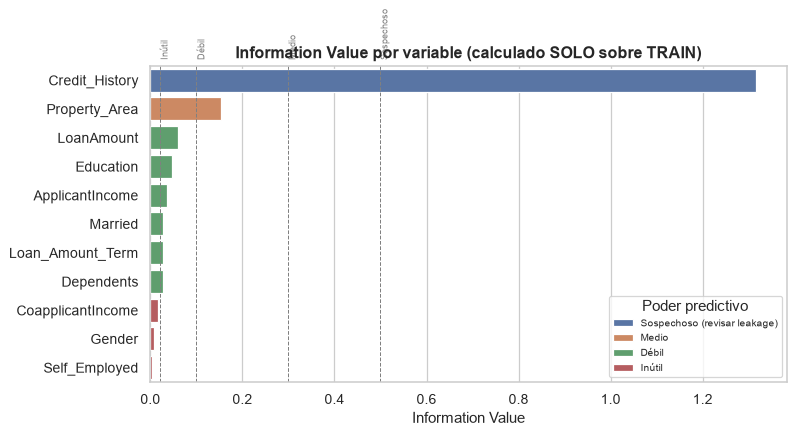

In [11]:
# Visualizamos el ranking con las zonas de corte de la tabla estándar
plt.figure(figsize=(9, 5))
sns.barplot(data=resumen_iv, y='variable', x='IV', hue='poder_predictivo', dodge=False)

for corte, etiqueta in [(0.02, 'Inútil'), (0.1, 'Débil'), (0.3, 'Medio'), (0.5, 'Sospechoso')]:
    plt.axvline(corte, color='grey', linestyle='--', linewidth=0.8)
    plt.text(corte, -0.7, etiqueta, rotation=90, fontsize=7, color='grey', va='bottom')

plt.title('Information Value por variable (calculado SOLO sobre TRAIN)')
plt.xlabel('Information Value')
plt.ylabel('')
plt.legend(title='Poder predictivo', fontsize=8)
plt.tight_layout()
plt.show()

**Cómo usar este ranking (y cómo NO usarlo):**

- ✅ **Sirve para descartar**: las variables con IV < 0.02 son candidatas a salir. Nos ahorra
  trabajo, reduce el riesgo de sobreajuste y hace el modelo más simple de mantener y explicar.
- ✅ **Sirve para conversar con el negocio**: si una variable que el negocio jura que es clave
  tiene IV = 0.005, hay que sentarse a entender por qué. O el dato está mal capturado, o la
  creencia del negocio era un mito.
- ❌ **NO sirve para armar el modelo final**: recuerda la desventaja del PDF, **el IV es
  univariante**. Si dos variables tienen IV alto pero están correlacionadas al 95%, el IV no te
  avisa: te las va a rankear altas a las dos. La selección final necesita mirar correlaciones,
  VIF y aporte multivariante.
- ❌ **NO es un juicio final**: una variable con IV bajo puede ser muy útil **en interacción** con
  otra. `ApplicantIncome` solo, no predice. `ApplicantIncome / LoanAmount` puede que sí.

### 5.8 Gráfico de WoE por bin: buscando la **monotonicidad**

El gráfico de WoE es la herramienta de diagnóstico del binning. Lo que queremos ver es una
**relación monótona**: que el WoE suba (o baje) de forma ordenada a lo largo de los bins.

¿Por qué nos importa tanto?
1. **Es lo que la regresión logística asume**: un único coeficiente por variable no puede capturar
   una relación en forma de U.
2. **Es defendible ante el negocio y ante el regulador**: "a mayor plazo, mayor riesgo" se puede
   sustentar. "El riesgo sube, baja, vuelve a subir y baja" no se sustenta — eso es ruido, y en
   TEST no se va a repetir.

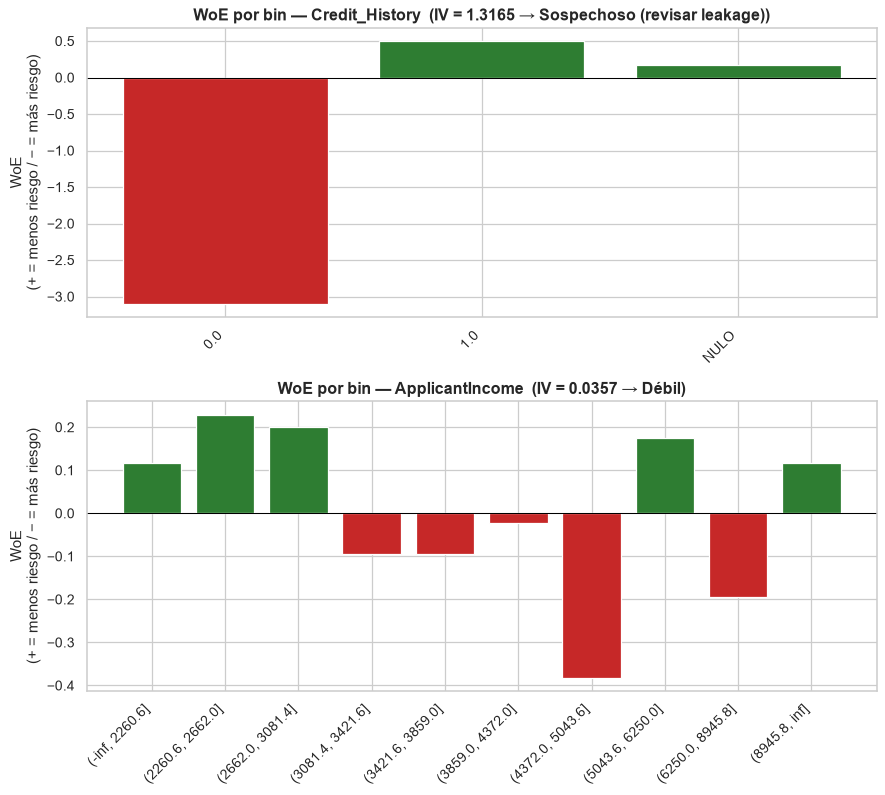

In [12]:
def graficar_woe(tabla, feature, iv, ax=None):
    """Grafica el WoE por bin. Barras verdes = menor riesgo, rojas = mayor riesgo."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))

    colores = ['#2e7d32' if w > 0 else '#c62828' for w in tabla['WoE']]
    ax.bar(tabla['bin'].astype(str), tabla['WoE'], color=colores)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'WoE por bin — {feature}  (IV = {iv:.4f} → {poder_predictivo(iv)})')
    ax.set_ylabel('WoE\n(+ = menos riesgo / − = más riesgo)')
    ax.tick_params(axis='x', rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    return ax


fig, axes = plt.subplots(2, 1, figsize=(10, 9))

# Categórica: relación clara y monótona
graficar_woe(tabla_ch, 'Credit_History', iv_ch, ax=axes[0])

# Numérica: relación NO monótona
graficar_woe(tabla_ai, 'ApplicantIncome', iv_ai, ax=axes[1])

plt.tight_layout()
plt.show()

**Lectura de los dos gráficos:**

- **`Credit_History` (arriba)**: perfecto. Barra roja muy larga para el mal historial, barra verde
  para el bueno, y el `NULO` en su propio nivel. La separación entre buenos y malos es enorme —
  que es justamente lo que dice el PDF que mide el WoE. Monótona y explicable.
- **`ApplicantIncome` (abajo)**: un desastre visual, y esa es la enseñanza. Las barras alternan
  verde y rojo **sin ningún orden**. No hay tendencia. Ese zigzag es **ruido muestral**, no señal:
  mira la columna `n` de su tabla en 7.6 y verás cuántos clientes hay por bin. Con esos volúmenes,
  **basta un puñado de casos para dar vuelta el signo** de una barra.

**¿Qué se hace con una variable no monótona?** Tres opciones, en orden de preferencia:
1. **Agrupar bins** con criterio (ej. 3 tramos de ingreso en vez de 10). Menos bins = más registros
   por bin = menos ruido, y una relación que puede aparecer.
2. **Construir un feature mejor** (el ratio ingreso/monto). Muchas veces la variable no es mala:
   está mal expresada.
3. **Descartarla**, si su IV además es bajo.

Lo que **nunca** se hace es mover los cortes hasta que el IV suba. Eso es la desventaja del PDF en
vivo: *"es fácil manipular el efecto según cómo se creen las categorías"*. Si el criterio para
elegir los bins es "el que me da mejor número", ya no estás modelando: estás sobreajustando.

### 5.9 Aplicando la transformación WoE

Hasta acá el WoE fue **diagnóstico**. Ahora lo usamos como **transformación**: reemplazamos el
valor original de cada cliente por el WoE de su bin.

El resultado es una tabla **100% numérica, sin nulos, sin outliers y en escala de log-odds**, lista
para una regresión logística. Fíjate lo que desaparece de golpe: no hay que imputar, no hay que
escalar, no hay que hacer one-hot encoding.

Lo construimos con la interfaz `fit` / `transform` de sklearn, y esa separación **no es un
capricho de estilo**: es la barrera anti-leakage hecha código.

- **`fit(X_train, y_train)`** → aprende los bins y los WoE. **Es el único momento que toca el
  target.**
- **`transform(X)`** → solo aplica lo aprendido. **Nunca mira el target.**

Si `transform` no recibe `y`, es **estructuralmente imposible** filtrar información del target de
test hacia las features. El diseño te protege del error.

In [13]:
class WOETransformer:
    """
    Transformador estilo sklearn que reemplaza cada variable por su WoE.

    Uso correcto (el único correcto):
        woe = WOETransformer().fit(X_train, y_train)
        X_train_woe = woe.transform(X_train)
        X_test_woe  = woe.transform(X_test)     # <- aplica, NO recalcula

    Parámetros
    ----------
    n_bins : int, default 10
    alpha : float, default 0.5
        Suavizado de Laplace.
    iv_minimo : float, default 0.0
        Si es > 0, descarta las variables con IV por debajo de este umbral
        (ej. 0.02 para eliminar las 'inútiles').
    """

    def __init__(self, n_bins=10, alpha=0.5, iv_minimo=0.0):
        self.n_bins = n_bins
        self.alpha = alpha
        self.iv_minimo = iv_minimo

    def fit(self, X, y):
        df = X.copy()
        df['__target__'] = np.asarray(y)

        self.mapas_, self.edges_, self.iv_, self.tablas_ = {}, {}, {}, {}

        for col in X.columns:
            # Aprendemos los cortes SOLO con train y los guardamos para reutilizarlos.
            _, edges = _binear(X[col], n_bins=self.n_bins)
            tabla, iv = calcular_woe_iv(df, col, '__target__', n_bins=self.n_bins,
                                        alpha=self.alpha, edges=edges)
            self.iv_[col] = iv
            if iv < self.iv_minimo:
                continue  # variable descartada por IV insuficiente
            self.edges_[col] = edges
            self.tablas_[col] = tabla
            self.mapas_[col] = dict(zip(tabla['bin'], tabla['WoE']))

        self.features_ = list(self.mapas_.keys())
        return self

    def transform(self, X):
        salida = pd.DataFrame(index=X.index)

        for col in self.features_:
            edges = self.edges_[col]
            if edges is not None:
                # Numérica: reutilizamos los MISMOS cortes aprendidos en train.
                binned, _ = _binear(X[col], n_bins=self.n_bins, edges=edges)
                bins_str = pd.Series(np.asarray(binned).astype(str), index=X.index)
            else:
                # Categórica: mismas etiquetas, nulos -> 'NULO'.
                bins_str = X[col].astype(str).where(X[col].notna(), 'NULO')

            # Categoría no vista en train -> WoE = 0 (neutro). No inventamos riesgo
            # sobre evidencia que nunca tuvimos.
            salida[col + '_woe'] = bins_str.map(self.mapas_[col]).fillna(0.0).astype(float)

        return salida

    def fit_transform(self, X, y):
        return self.fit(X, y).transform(X)

In [14]:
# fit SOLO con train ...
woe_transformer = WOETransformer(n_bins=10, alpha=0.5, iv_minimo=0.02).fit(X_train, y_train)

# ... y transform a ambos conjuntos
X_train_woe = woe_transformer.transform(X_train)
X_test_woe = woe_transformer.transform(X_test)

descartadas = [c for c in X_train.columns if c not in woe_transformer.features_]

print(f"Variables originales : {X_train.shape[1]}")
print(f"Variables tras WoE   : {X_train_woe.shape[1]}  "
      f"(se descartaron las de IV < {woe_transformer.iv_minimo})")
print(f"Descartadas ({len(descartadas)})      : {descartadas}")
for c in descartadas:
    print(f"    - {c:22s} IV = {woe_transformer.iv_[c]:.4f}  -> {poder_predictivo(woe_transformer.iv_[c])}")
print(f"\nNulos en X_train_woe : {int(X_train_woe.isnull().sum().sum())}")
print(f"Nulos en X_test_woe  : {int(X_test_woe.isnull().sum().sum())}")

X_train_woe.head()

Variables originales : 11
Variables tras WoE   : 8  (se descartaron las de IV < 0.02)
Descartadas (3)      : ['Gender', 'Self_Employed', 'CoapplicantIncome']
    - Gender                 IV = 0.0080  -> Inútil
    - Self_Employed          IV = 0.0037  -> Inútil
    - CoapplicantIncome      IV = 0.0171  -> Inútil

Nulos en X_train_woe : 0
Nulos en X_test_woe  : 0


,Married_woe,Dependents_woe,Education_woe,ApplicantIncome_woe,LoanAmount_woe,Loan_Amount_Term_woe,Credit_History_woe,Property_Area_woe
Loan_ID,,,,,,,,
LP001002,-0.215566,-0.006385,0.119442,0.174527,-0.676076,-0.012801,0.499929,-0.027514
LP001003,0.115923,-0.115202,0.119442,-0.381574,0.071138,-0.012801,0.499929,-0.502065
LP001005,0.115923,-0.006385,0.119442,0.199922,0.202067,-0.012801,0.499929,-0.027514
LP001006,0.115923,-0.006385,-0.398190,0.229336,0.071138,-0.012801,0.499929,-0.027514
LP001008,-0.215566,-0.006385,0.119442,0.174527,0.176673,-0.012801,0.499929,-0.027514


**Cero nulos, todo numérico, todo en la misma escala** — y sin haber imputado ni escalado una sola
variable. Esa es la propuesta de valor del WoE.

Comprobemos que efectivamente funciona en una regresión logística:

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

modelo_woe = LogisticRegression(random_state=seed, max_iter=1000)
modelo_woe.fit(X_train_woe, y_train)

auc_train = roc_auc_score(y_train, modelo_woe.predict_proba(X_train_woe)[:, 1])
auc_test = roc_auc_score(y_test, modelo_woe.predict_proba(X_test_woe)[:, 1])

print(f"AUC train : {auc_train:.4f}")
print(f"AUC test  : {auc_test:.4f}")

# Con WoE, los coeficientes son directamente comparables entre sí: todas las
# variables están en la misma escala (log-odds).
#
# SIGNO ESPERADO: con nuestra convención (WoE = ln(%No-Evento / %Evento)), un WoE alto
# es un bin de MENOS riesgo. Si al subir el WoE baja P(evento), el coeficiente TIENE que
# ser negativo. El veredicto de abajo es lógica real, no un comentario: si algún día el
# signo se invierte, el texto lo dirá solo.
SIGNO_ESPERADO = -1  # negativo, por la convención fijada en 7.1

coef_woe = pd.DataFrame({
    'variable': X_train_woe.columns,
    'coeficiente': modelo_woe.coef_[0],
    'IV': [woe_transformer.iv_[c.replace('_woe', '')] for c in X_train_woe.columns],
})
coef_woe['signo_ok'] = np.sign(coef_woe['coeficiente']) == SIGNO_ESPERADO
coef_woe['veredicto'] = np.where(coef_woe['signo_ok'], 'esperado', '⚠️ SIGNO INVERTIDO')
coef_woe = coef_woe.sort_values('coeficiente', key=abs, ascending=False).reset_index(drop=True)

n_ok = int(coef_woe['signo_ok'].sum())
n_tot = len(coef_woe)
print(f"Coeficientes con el signo esperado (negativo): {n_ok} de {n_tot}")
print(f"Mediana de los coeficientes: {coef_woe['coeficiente'].median():+.3f}   "
      f"(referencia teórica: {SIGNO_ESPERADO:+d})")
if n_ok < n_tot:
    invertidas = coef_woe.loc[~coef_woe['signo_ok'], 'variable'].tolist()
    print(f"⚠️  Revisar (se comportan al revés en presencia de las demás): {invertidas}")
else:
    print("✅ Ninguna variable cambia de signo respecto de su análisis univariante.")

coef_woe.round(4)

AUC train : 0.8267
AUC test  : 0.7189


Coeficientes con el signo esperado (negativo): 8 de 8
Mediana de los coeficientes: -0.833   (referencia teórica: -1)
✅ Ninguna variable cambia de signo respecto de su análisis univariante.


,variable,coeficiente,IV,signo_ok,veredicto
0,LoanAmount_woe,-1.2664,0.0595,True,esperado
1,Property_Area_woe,-1.2384,0.1536,True,esperado
2,Credit_History_woe,-1.0710,1.3165,True,esperado
3,ApplicantIncome_woe,-0.8763,0.0357,True,esperado
4,Married_woe,-0.7904,0.0281,True,esperado
5,Dependents_woe,-0.6937,0.0272,True,esperado
6,Education_woe,-0.6720,0.0474,True,esperado
7,Loan_Amount_Term_woe,-0.0754,0.0278,True,esperado


### El coeficiente ≈ −1: el chequeo de sanidad más barato de un scorecard

Como el WoE ya viene **en escala de log-odds**, el coeficiente de una regresión logística sobre
WoE no es un número cualquiera: **tiene un valor esperado, y con nuestra convención ese valor es
≈ −1**. Que salga cerca de −1 no es casualidad ni suerte — es la prueba de que la transformación
está bien hecha.

**¿Por qué negativo?** Recuerda la convención que fijamos en 7.1: `WoE = ln(%No-Evento / %Evento)`,
con evento = 1 = "malo". Entonces **WoE alto = bin de MENOR riesgo**. Si al subir el WoE el riesgo
**baja**, el coeficiente que lo acompaña **tiene que ser negativo**. El signo no es un detalle
estético: es la convención hablando.

**¿Y por qué de magnitud 1?** Ésta es la parte bonita. La regresión logística modela:

$$ \ln\left(\frac{P(\text{evento})}{1-P(\text{evento})}\right) = \beta_0 + \beta_1 \cdot WoE $$

El lado izquierdo son **log-odds del evento**. Y el WoE, por construcción, **ya es** un log-odds
(el del no-evento contra el evento) — es decir, ya llega **en las unidades exactas del modelo, pero
con el signo dado vuelta**. Al modelo no le queda nada que reescalar: solo tiene que **girar el
signo**, y eso es multiplicar por −1. Por eso el factor de reescalado ideal es exactamente **−1**:
la variable llega **pre-traducida al idioma del modelo**.

> 🎯 **Y por eso es un diagnóstico, no una curiosidad.** El β ≈ −1 es una **predicción teórica** que
> puedes contrastar. Cuando una transformación tiene un valor esperado conocido, cualquier
> desviación **significa algo**. Eso es infinitamente más útil que un coeficiente sin referencia,
> donde no tienes con qué comparar.

**Cómo leer un coeficiente, entonces:**

| Coeficiente | Lectura | Qué hacer |
|---|---|---|
| **≈ −1** | La variable está bien codificada y se comporta como decía su análisis univariante | Nada. Está sano. |
| **Negativo pero lejos de −1** | Normal en un modelo multivariante: la variable comparte información con otras, o la regularización lo encogió | Mirar correlaciones entre variables |
| **≈ 0** | La variable no aporta *en presencia de las demás* (aunque su IV sea alto) | Candidata a salir: es redundante |
| **POSITIVO** 🚨 | **Se comporta al revés de lo esperado** | **Investigar de verdad** |

**El caso positivo es el único que es una alarma de verdad**, y tiene tres causas típicas:
1. **Relación no monótona** (como `ApplicantIncome` en 7.6): el binning promedió efectos opuestos.
2. **Un bin mal construido**: muy pequeño, o que mezcla poblaciones que el negocio distingue.
3. **Colinealidad**: la variable, *en presencia de las demás*, se da vuelta. ¿Se acuerdan de la
   desventaja del PDF? **"Es una medida univariante, no considera la correlación entre las
   variables independientes."** El IV rankea variables **una por una**; el modelo las ve **todas
   juntas**. **Un cambio de signo es exactamente ese choque**, y es la señal de que el ranking
   univariante te estaba contando una historia incompleta.

#### ⚠️ La trampa del signo (la confusión #1 del WoE en la práctica)

Si abres un libro, un blog o un paquete de scorecards y lees que **"el coeficiente ideal es +1"**,
**no están equivocados**: están usando la convención inversa (`ln(%Evento / %No-Evento)`), o
definieron el evento como el 0 en vez del 1. Con esa convención **todos los signos se invierten**:
WoE alto pasa a significar *más* riesgo, y el coeficiente ideal pasa a ser **+1**.

> **El signo no es una propiedad del WoE. Es una consecuencia de la convención que elegiste.**
> Ninguna de las dos es "la correcta". Lo único que importa es que sea **CONSISTENTE**: que la
> fórmula, los gráficos, la lectura de los bins y la interpretación de los coeficientes hablen
> todos el mismo idioma. **Mezclar convenciones dentro de un mismo proyecto es la forma más
> rápida de leer un modelo sano como si estuviera roto** — o, mucho peor, al revés.

Verifiquemos que el −1 no es un cuento: vamos a **medirlo**.

In [16]:
# El -1 teórico aparece LIMPIO en la regresión UNIVARIANTE: una variable sola, sin
# competencia de las demás y sin regularización que la encoja. Es el experimento
# controlado que aísla la propiedad que acabamos de explicar.
#
# C=1e9 -> desactiva de hecho la regularización L2 que sklearn aplica por defecto.
# (La regularización empuja TODOS los coeficientes hacia 0: es una decisión de
#  modelado legítima, pero acá contaminaría la medición.)
univ = []
for col in X_train_woe.columns:
    b_reg = (LogisticRegression(random_state=seed, max_iter=1000)
             .fit(X_train_woe[[col]], y_train).coef_[0][0])
    b_sin = (LogisticRegression(random_state=seed, max_iter=5000, C=1e9)
             .fit(X_train_woe[[col]], y_train).coef_[0][0])
    univ.append({'variable': col, 'beta_regularizado': b_reg, 'beta_sin_regularizar': b_sin,
                 'error_vs_-1': abs(b_sin - SIGNO_ESPERADO)})

univ = pd.DataFrame(univ).sort_values('error_vs_-1').reset_index(drop=True)

print("REGRESIÓN UNIVARIANTE — acá el β tiene que dar el ideal teórico")
print("=" * 74)
print(f"{'variable':24s} {'β (default)':>12s} {'β (sin reg.)':>13s} {'|β-(-1)|':>10s}")
print("-" * 74)
for _, r in univ.iterrows():
    print(f"{r['variable']:24s} {r['beta_regularizado']:+12.4f} {r['beta_sin_regularizar']:+13.4f} "
          f"{r['error_vs_-1']:10.4f}")
print("-" * 74)

err_max = univ['error_vs_-1'].max()
todos_neg = bool((univ['beta_sin_regularizar'] < 0).all())
print(f"\nTodos los β univariantes son negativos : {todos_neg}")
print(f"Mediana (sin regularizar)              : {univ['beta_sin_regularizar'].median():+.4f}"
      f"   <- referencia teórica: {SIGNO_ESPERADO:+d}")
print(f"Desviación máxima respecto de -1       : {err_max:.4f}  ({univ.iloc[-1]['variable']})")
print()
if not todos_neg:
    invertidas_u = univ.loc[univ['beta_sin_regularizar'] > 0, 'variable'].tolist()
    print(f"🚨 SIGNO INVERTIDO en {invertidas_u}: una variable que el WoE codificó como")
    print("   'de menor riesgo' se comporta al revés. Revisar binning y definición de negocio.")
elif err_max < 0.25:
    print("✅ Clavado en -1: todos los β caen sobre el ideal teórico. La transformación WoE está")
    print("   bien construida — cada variable llega al modelo ya expresada en log-odds, y al")
    print("   modelo solo le queda girarle el signo.")
else:
    print("✅ Todos los β son negativos (el signo, que es lo que diagnostica, está bien) y la")
    print(f"   mediana cae sobre el ideal. La que más se aleja es '{univ.iloc[-1]['variable']}':")
    print("   vale la pena mirarle el binning — suele ser un bin chico moviendo el promedio.")

print()
print("Nota sobre las dos columnas: el β 'default' sale sistemáticamente MÁS CERCA DE CERO")
print("que el β sin regularizar. No es un error — es la regularización L2 de sklearn")
print("haciendo su trabajo: encoge los coeficientes hacia 0 para evitar sobreajuste.")
print("Por eso el modelo multivariante de arriba tampoco da -1 exacto, y no debe alarmarte:")
print("lo que se diagnostica con el ideal teórico es EL SIGNO; la magnitud la mueven")
print("la regularización y la correlación entre variables.")

REGRESIÓN UNIVARIANTE — acá el β tiene que dar el ideal teórico
variable                  β (default)  β (sin reg.)   |β-(-1)|
--------------------------------------------------------------------------
Dependents_woe                -0.7091       -0.9971     0.0029
Education_woe                 -0.8152       -0.9964     0.0036
Property_Area_woe             -0.9392       -1.0074     0.0074
Credit_History_woe            -1.0064       -1.0249     0.0249
LoanAmount_woe                -0.8745       -1.0300     0.0300
ApplicantIncome_woe           -0.7925       -1.0327     0.0327
Married_woe                   -0.7855       -1.0960     0.0960
Loan_Amount_Term_woe          -0.7743       -1.1276     0.1276
--------------------------------------------------------------------------

Todos los β univariantes son negativos : True
Mediana (sin regularizar)              : -1.0275   <- referencia teórica: -1
Desviación máxima respecto de -1       : 0.1276  (Loan_Amount_Term_woe)

✅ Clavado en -1: todos

### 5.10 🚨 La advertencia crítica: WoE/IV calculado sobre TODO el dataset es **LEAKAGE**

Este es el punto más importante de toda la sección. Es también el error más común, y el más difícil
de detectar, porque **el código no falla y las métricas se ven mejor**.

#### ¿Por qué es leakage?

El WoE **se calcula usando el target**. Cada número de la columna `WoE` es una función de los
eventos y no-eventos observados. Entonces, si calculamos el WoE sobre el dataset completo:

1. El WoE del bin *"ingreso entre 3,000 y 4,000"* fue calculado usando, entre otros, **el target de
   los clientes de test**.
2. Al transformar test, a esos clientes se les asigna un número que **contiene información sobre su
   propio resultado**.
3. El modelo evalúa en test con una feature que ya "vio" la respuesta.
4. **El AUC de test sube.** Y es mentira. No mide capacidad de generalizar: mide cuánta información
   del target se filtró.

Es el mismo principio que ya vimos con la imputación y el escalado, pero **mucho más grave**:
`SimpleImputer` usa solo `X`; el WoE usa **`X` e `y`**. La fuga es directa.

#### La consecuencia de negocio

Esto no es un tecnicismo académico. Presentas al comité un modelo con AUC 0.78, se aprueba, se
despliega... y en producción rinde 0.71. Los clientes nuevos **no traen su target puesto**: no hay
ningún WoE que se haya podido calcular con su resultado, porque su resultado todavía no ocurrió.
**La brecha entre tu AUC de laboratorio y tu AUC real es exactamente lo que filtraste.** Y el costo
no lo pagas tú: lo paga el negocio, que dimensionó campañas, provisiones y metas con un número que
nunca existió.

Vamos a demostrarlo con el caso más brutal posible: una variable de **ruido puro**.

In [17]:
# Semilla PROPIA de esta celda, con nombre propio: NO pisamos ningún `rng` global de
# otras secciones, y reconstruirla acá hace que esta celda sea idempotente (puedes
# re-ejecutarla en clase las veces que quieras y da exactamente lo mismo).
rng_ruido = np.random.RandomState(seed)

# Una variable 100% aleatoria: por construcción NO tiene ninguna relación con el target.
# Cualquier AUC distinta de 0.5 que produzca es, por definición, información filtrada.
ruido_train = pd.DataFrame({'ruido': rng_ruido.randint(0, 40, size=len(X_train))}, index=X_train.index)
ruido_test = pd.DataFrame({'ruido': rng_ruido.randint(0, 40, size=len(X_test))}, index=X_test.index)

# --- FORMA CORRECTA: fit en TRAIN, transform a TEST ---
woe_ok = WOETransformer(n_bins=40).fit(ruido_train, y_train)
auc_ok = roc_auc_score(y_test, LogisticRegression(random_state=seed, max_iter=1000)
                       .fit(woe_ok.transform(ruido_train), y_train)
                       .predict_proba(woe_ok.transform(ruido_test))[:, 1])

# --- FORMA INCORRECTA: fit sobre TRAIN + TEST juntos (el error clásico) ---
ruido_todo = pd.concat([ruido_train, ruido_test])
y_todo = pd.concat([y_train, y_test])

woe_mal = WOETransformer(n_bins=40).fit(ruido_todo, y_todo)   # <-- ¡acá se filtra el target de test!
auc_mal = roc_auc_score(y_test, LogisticRegression(random_state=seed, max_iter=1000)
                        .fit(woe_mal.transform(ruido_train), y_train)
                        .predict_proba(woe_mal.transform(ruido_test))[:, 1])

iv_ruido = woe_ok.iv_['ruido']
N_BINS_RUIDO = 40

print("Variable de RUIDO PURO (sin ninguna relación real con el target)")
print("-" * 72)
print(f"IV en TRAIN ({N_BINS_RUIDO} bins)       : {iv_ruido:.4f}  -> '{poder_predictivo(iv_ruido)}' (!!)")
print(f"AUC test — forma CORRECTA   : {auc_ok:.4f}  <- la verdad: no predice nada")
print(f"AUC test — forma INCORRECTA : {auc_mal:.4f}  <- señal INVENTADA por el leakage")
print(f"Ganancia 100% ficticia      : {auc_mal - auc_ok:+.4f}")
print()
print(f"Clientes por bin: {len(X_train)} registros / {N_BINS_RUIDO} bins ≈ {len(X_train) / N_BINS_RUIDO:.0f} por bin")
print(f"-> con tan poca gente por bin, el azar basta para fabricar un IV '{poder_predictivo(iv_ruido)}'")

Variable de RUIDO PURO (sin ninguna relación real con el target)
------------------------------------------------------------------------
IV en TRAIN (40 bins)       : 0.3742  -> 'Fuerte' (!!)
AUC test — forma CORRECTA   : 0.4553  <- la verdad: no predice nada
AUC test — forma INCORRECTA : 0.6050  <- señal INVENTADA por el leakage
Ganancia 100% ficticia      : +0.1497

Clientes por bin: 447 registros / 40 bins ≈ 11 por bin
-> con tan poca gente por bin, el azar basta para fabricar un IV 'Fuerte'


**Lean ese resultado con calma.** La variable es `rng_ruido.randint()`. Números aleatorios. No
tiene absolutamente ninguna relación con que un crédito se apruebe o no. Y sin embargo, calculando
el WoE sobre todo el dataset, **aparece señal en test donde no hay nada**: mira la diferencia entre
la forma correcta y la incorrecta. **Todo ese salto es información del target de test que se filtró
hacia las features.**

> 🔎 **Un matiz honesto sobre la "forma CORRECTA":** su AUC tampoco da exactamente 0.50. Con un
> test de pocas filas, una variable inútil rara vez marca 0.500 clavado — oscila alrededor de 0.5
> por puro azar muestral. Lo que importa no es el decimal, es **la brecha entre las dos formas**:
> eso es lo que el leakage inventó.

#### Regalo extra: la segunda trampa está en la misma salida

Miren la primera línea. El **IV del ruido puro, calculado correctamente solo en train**, cae en una
categoría que la tabla estándar consideraría aprovechable. **¡De ruido aleatorio!**

¿Por qué? Porque le pedimos **40 bins**: mira la última línea de la salida y verás cuántos clientes
quedan en cada uno. Con tan poca gente, algunos bins salen 100% buenos y otros 100% malos **por puro
azar**, y el IV suma esas diferencias como si fueran señal. Esta es, literalmente, la desventaja
del PDF hecha número:
*"es fácil manipular/sobreajustar el efecto según cómo se creen las categorías"*.

La defensa es simple y hay que aplicarla siempre: **exigir un volumen mínimo por bin** (regla
práctica: **≥ 5% de la muestra**, y nunca menos de ~30 casos) y **menos bins de los que uno cree
que necesita**. Un IV alto obtenido con bins diminutos no es poder predictivo: es memoria.

Y noten la conclusión doble, que es lo que hay que llevarse: **el IV de train no valida nada.**
Esta variable sacó un IV respetable en train y, medida honestamente en test, no predice nada. La
única prueba de que una variable sirve es su comportamiento en datos que el modelo **nunca vio**.

#### El peligro del leakage, resumido

- **El código no falla.** No hay error, no hay warning, no hay nada rojo en pantalla.
- **Las métricas mejoran.** Y como mejoran, uno tiende a no cuestionarlas. *El leakage nunca se
  presenta como un bug: se presenta como un buen resultado.* Por eso hay que sospechar
  **especialmente** de las mejoras que no se pueden explicar.
- **En producción, no existe.** El WoE del cliente nuevo se calculó sin su target, porque su target
  aún no ocurrió. La ventaja desaparece y el modelo rinde menos de lo prometido.

#### Las reglas, entonces

1. **`fit` SOLO sobre train.** Siempre. Sin excepciones.
2. **A test solo se le hace `transform`.** Si estás calculando algo sobre test, algo va mal.
3. **Cuidado con el `train_test_split` tardío.** Si transformas y *después* divides, ya filtraste.
   Divide primero, siempre.
4. **En validación cruzada**, el WoE se recalcula **dentro de cada fold**, con los datos de
   entrenamiento de ese fold. Un WoE calculado una sola vez antes del CV contamina todos los folds.
   (Por eso conviene envolver el `WOETransformer` en un `Pipeline` de sklearn: el `Pipeline`
   respeta la frontera fold por fold automáticamente.)
5. **Si una variable tiene IV > 0.5, sospecha antes de celebrar.** Es más probable que sea leakage
   que un hallazgo.

> 💡 **La idea para llevarse a casa:** todo lo que uses el target para calcular —WoE, IV, target
> encoding, medias por categoría, imputaciones basadas en `y`— **es un parámetro que se aprende, y
> los parámetros se aprenden SOLO en train.** Preguntarse *"para calcular esto, ¿usé el target?"*
> es la forma más rápida de detectar leakage antes de que llegue al comité.

---
## 5.11 Exportación

Guardamos las features **transformadas a WoE** (train y test), el **transformador** (para
reproducir la transformación en producción) y la **tabla de IV** — que el NB07 usará como una de
las tres fuentes de selección de variables.

> Las features WoE son una **representación alternativa**, pensada sobre todo para regresión
> logística / scorecards. El pipeline "clásico" (imputación + encoding + escalado) sigue en el
> NB06 en paralelo. Ambas ramas parten del mismo `04_train`.

In [18]:
# Adjuntamos metadatos y target a las features WoE ya calculadas en 5.9
train_woe_out = X_train_woe.copy()
train_woe_out[SEGMENT_COL] = train_raw[SEGMENT_COL]
train_woe_out[target] = y_train

test_woe_out = X_test_woe.copy()
test_woe_out[SEGMENT_COL] = test_raw[SEGMENT_COL]
test_woe_out[target] = y_test

save_stage(train_woe_out, "05_train_woe")
save_stage(test_woe_out, "05_test_woe")

# El transformador WoE (aprende bins + WoE SOLO en train)
save_artifact(woe_transformer, "woe_transformer")

# Tabla de IV para el NB07
iv_dict = {
    "iv_por_variable": resumen_iv.set_index("variable")["IV"].round(6).to_dict(),
    "poder_predictivo": resumen_iv.set_index("variable")["poder_predictivo"].to_dict(),
    "descartables_iv_bajo": resumen_iv.loc[resumen_iv["IV"] < 0.02, "variable"].tolist(),
    "sospechosas_leakage": resumen_iv.loc[resumen_iv["IV"] > 0.5, "variable"].tolist(),
}
save_report(iv_dict, "iv_table")
save_table(resumen_iv.set_index("variable"), "iv_ranking")

print(f"Features WoE → 05_train_woe {train_woe_out.shape} | transformador → joblib | iv_ranking.csv")

Features WoE → 05_train_woe (447, 10) | transformador → joblib | iv_ranking.csv


## 🔍 Lectura analítica del IV

El IV convierte "¿qué variable sirve?" en un número. Pero hay que leerlo con criterio.

In [19]:
print("RANKING DE PODER PREDICTIVO (Information Value)")
print("=" * 60)
print(resumen_iv.round(4).to_string(index=False))
print("=" * 60)
top = resumen_iv.iloc[0]
print()
print(f"1. La variable dominante es '{top['variable']}' con IV = {top['IV']:.3f}.")
if top["IV"] > 0.5:
    print(f"   ⚠️  IV > 0.5 = SOSPECHOSO. No es una gran feature: casi seguro que ES el")
    print(f"      target disfrazado (la regla del comité de crédito). Ver NB01 §1.3.")
print()
utiles = resumen_iv[(resumen_iv['IV'] >= 0.02) & (resumen_iv['IV'] <= 0.5)]
print(f"2. Variables con poder REAL (0.02 ≤ IV ≤ 0.5): {len(utiles)}")
print(f"     {', '.join(utiles['variable'].tolist())}")
print()
inutiles = resumen_iv[resumen_iv['IV'] < 0.02]
print(f"3. Candidatas a descartar (IV < 0.02): {len(inutiles)}")
print(f"     {', '.join(inutiles['variable'].tolist()) if len(inutiles) else 'ninguna'}")
print()
print(">> Pero OJO: el IV es UNIVARIANTE. Dos variables con IV alto pueden ser la misma")
print("   información. La selección final (NB07) cruza IV con correlación, VIF y aporte")
print("   multivariante. El IV descarta, no decide.")
print()
print("Siguiente paso → 06_pipeline_proc.ipynb")

RANKING DE PODER PREDICTIVO (Information Value)
         variable     IV             poder_predictivo
   Credit_History 1.3165 Sospechoso (revisar leakage)
    Property_Area 0.1536                        Medio
       LoanAmount 0.0595                        Débil
        Education 0.0474                        Débil
  ApplicantIncome 0.0357                        Débil
          Married 0.0281                        Débil
 Loan_Amount_Term 0.0278                        Débil
       Dependents 0.0272                        Débil
CoapplicantIncome 0.0171                       Inútil
           Gender 0.0080                       Inútil
    Self_Employed 0.0037                       Inútil

1. La variable dominante es 'Credit_History' con IV = 1.316.
   ⚠️  IV > 0.5 = SOSPECHOSO. No es una gran feature: casi seguro que ES el
      target disfrazado (la regla del comité de crédito). Ver NB01 §1.3.

2. Variables con poder REAL (0.02 ≤ IV ≤ 0.5): 7
     Property_Area, LoanAmount, Education, 